# Prática 1 · Classificando imagens com CLIP, sem treinar nada

**Desenvolvimento de Aplicações Interativas com LLMs Multimodais · Encontro 1 · PUC Minas**
Professor: Maurício Rodrigues da Silva

**Tempo:** 25 minutos · **Ambiente:** Google Colab (GPU ajuda, mas CPU funciona) · **Não precisa de chave de API**

### Objetivo
Ver o espaço compartilhado entre texto e imagem funcionando: classificar fotos suas usando só rótulos em texto, entender de onde vêm as probabilidades e testar os limites do modelo.

### Entrega
- Seu nome na célula de identificação.
- Os resultados com 3 fotos suas e a comparação entre português e inglês, com as células executadas.
- O quiz do final respondido.

## Identificação

Preencha seu nome na célula abaixo e rode a célula antes de começar. Ele aparece no resumo do quiz, no final do notebook.

In [1]:
ALUNO = "Tales Rodrigo Ferreira Kerschner"        # seu nome completo, entre as aspas
MATRICULA = ""    # sua matrícula (opcional)

print("Aluno:", ALUNO or "(preencha o nome acima)")

Aluno: Tales Rodrigo Ferreira Kerschner


## 1. Conceitos que vamos usar

**Embedding.** Um vetor de números que representa um conteúdo. Conteúdos parecidos geram vetores próximos.

**Espaço compartilhado.** O CLIP tem dois encoders, um de imagem e um de texto, treinados juntos para que a foto de um cachorro e a frase "a photo of a dog" gerem vetores próximos. Por isso dá para comparar diretamente uma imagem com um texto.

**Similaridade do cosseno.** Mede o ângulo entre dois vetores: 1 significa mesma direção, 0 significa nenhuma relação. Como o CLIP entrega vetores normalizados (tamanho 1), o cosseno é simplesmente o produto escalar.

**Logits e temperatura.** O CLIP multiplica as similaridades por um fator aprendido no treino (`logit_scale`), que funciona como o inverso de uma temperatura: amplia as diferenças antes do softmax.

**Softmax.** Transforma os logits em probabilidades que somam 1. Atenção: é uma probabilidade **relativa aos rótulos oferecidos**. Se nenhum rótulo estiver certo, o softmax ainda distribui 100% entre eles.

**Zero-shot.** Classificar categorias que o modelo nunca viu como classe de treino, apenas descrevendo-as em texto.

### 1.1 Como o CLIP foi treinado

O CLIP (Radford et al., 2021, OpenAI) foi treinado com cerca de **400 milhões de pares de imagem e legenda** coletados da internet. Ninguém rotulou classes à mão: a própria legenda que acompanhava a foto serviu de supervisão.

O treino é **contrastivo**. Em cada lote com N pares, o modelo calcula o cosseno entre **todas** as imagens e **todos** os textos, formando uma matriz N × N. O objetivo é deixar alto o cosseno dos N pares certos (a diagonal) e baixo o dos N² − N pares errados. Um exemplo com 3 pares:

| | "um cachorro na grama" | "uma pizza na mesa" | "um carro vermelho" |
| --- | --- | --- | --- |
| foto do cachorro | **alto** | baixo | baixo |
| foto da pizza | baixo | **alto** | baixo |
| foto do carro | baixo | baixo | **alto** |

No CLIP real, cada lote tinha 32.768 pares, ou seja, mais de 1 bilhão de comparações por passo. Depois do treino, qualquer frase vira um vetor no mesmo espaço das imagens. **Classificar passa a ser escolher a frase mais próxima da imagem**: é isso que torna o zero-shot possível.

### 1.2 O caminho de uma imagem e de um texto até o vetor

```
foto ──► 224 × 224 pixels ──► 49 patches ──► encoder de imagem (ViT) ──► vetor de 512 ──► normaliza ─┐
                                                                                                     ├──► cosseno
"a photo of a dog" ──► tokens ──► encoder de texto (Transformer) ──► vetor de 512 ──► normaliza ─────┘
```

- **Imagem.** O processador redimensiona a foto para 224 × 224 pixels e padroniza as cores. O modelo que usamos, `clip-vit-base-patch32`, corta a imagem em **patches** de 32 × 32 pixels: (224 / 32)² = 7 × 7 = **49 patches**, a mesma ideia do slide "Do pixel ao token". Cada patch vira um vetor, o Transformer processa os 49 juntos (pela atenção, cada patch "olha" para os outros) e um vetor final resume a imagem inteira.
- **Texto.** A frase é quebrada em tokens (no máximo 77), passa por um Transformer de texto e também vira um vetor.
- **Projeção e normalização.** Uma camada final leva os dois vetores para o mesmo tamanho, 512 números, e os normaliza para comprimento 1.

### 1.3 Da similaridade à probabilidade

A similaridade do cosseno entre o vetor da imagem $\mathbf{u}$ e o do texto $\mathbf{v}$ é

$$\cos(\mathbf{u}, \mathbf{v}) = \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\| \, \|\mathbf{v}\|}$$

Como os dois vetores têm comprimento 1, o denominador vale 1 e o cosseno é só o produto escalar. Para cada rótulo $i$, o CLIP calcula um logit multiplicando o cosseno pela escala aprendida $s$ (cerca de 100) e aplica o softmax:

$$\text{logit}_i = s \cdot \cos_i \qquad\qquad p_i = \frac{e^{\text{logit}_i}}{\sum_j e^{\text{logit}_j}}$$

**Exemplo numérico.** Três rótulos com cossenos 0,28, 0,24 e 0,20:

| | rótulo 1 | rótulo 2 | rótulo 3 |
| --- | --- | --- | --- |
| cosseno | 0,28 | 0,24 | 0,20 |
| softmax **sem** escala (s = 1) | 34,7% | 33,3% | 32,0% |
| softmax **com** escala (s = 100) | 98,2% | 1,8% | 0,03% |

Sem a escala, o modelo pareceria indeciso; com ela, uma diferença de 0,04 no cosseno vira 98% contra 2%. A escala funciona como o inverso de uma **temperatura**: quanto maior, mais "decidida" a distribuição. Na seção 4 você vai refazer essa conta com os números reais.

In [2]:
# No Colab, transformers já vem instalado. Fora dele: pip install transformers torch pillow requests
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

dev = "cuda" if torch.cuda.is_available() else "cpu"
NOME = "openai/clip-vit-base-patch32"
modelo = CLIPModel.from_pretrained(NOME).to(dev).eval()
proc = CLIPProcessor.from_pretrained(NOME)
print("Modelo carregado em", dev)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Modelo carregado em cuda


**O que esta célula faz**

- `dev` escolhe onde rodar: na GPU (`cuda`), se o Colab tiver uma, ou na CPU. Para inferência com poucas imagens, a CPU também funciona, só que mais devagar.
- `CLIPModel.from_pretrained(NOME)` baixa do Hugging Face os pesos já treinados (cerca de 600 MB, só na primeira vez) e monta os dois encoders.
- `.eval()` coloca o modelo em modo de avaliação: desliga comportamentos usados só no treino, como o dropout.
- `CLIPProcessor` reúne o **tokenizador** (texto → tokens) e o **processador de imagem** (redimensiona e padroniza a foto). Ele prepara as entradas no formato que o modelo espera.

## 2. Suas imagens

Envie 3 fotos do seu celular ou computador. Fotos de objetos, animais, comida ou lugares funcionam bem.

In [3]:
# Envie uma ou mais imagens para o ambiente.
# Enviei as três fotos pelo painel Arquivos do Colab; o seletor só abre se elas não estiverem na pasta.
import os
enviados = ["bananas.jpg", "cachorro.jpg", "cubo-magico.jpg"]
if not all(os.path.exists(c) for c in enviados):
    from google.colab import files
    enviados = list(files.upload().keys())
print("Arquivos:", enviados)

Arquivos: ['bananas.jpg', 'cachorro.jpg', 'cubo-magico.jpg']


`files.upload()` abre o seletor de arquivos do Colab e grava as fotos na pasta do notebook; `enviados` guarda os nomes. A função `abrir` lê a foto e converte para RGB (3 canais de cor), o que evita erro com PNG transparente, que tem um quarto canal.

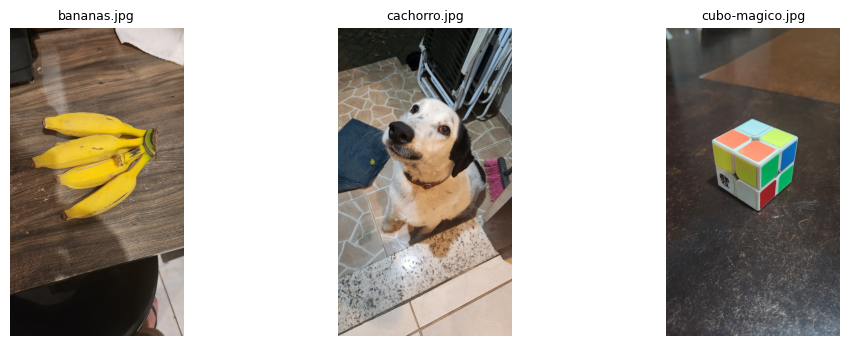

In [4]:
def abrir(caminho):
    return Image.open(caminho).convert("RGB")   # convert: evita erro com PNG transparente


fig, eixos = plt.subplots(1, len(enviados), figsize=(4 * len(enviados), 4), squeeze=False)
for ax, c in zip(eixos[0], enviados):
    ax.imshow(abrir(c)); ax.set_title(c, fontsize=9); ax.axis("off")
plt.show()

## 3. Classificação zero-shot

A função recebe uma imagem e uma lista de rótulos e devolve as probabilidades. Ela também devolve as **similaridades do cosseno**, que vamos usar mais adiante.

**Como a função `classificar` funciona, linha a linha**

1. `@torch.no_grad()` desliga o cálculo de gradientes. Gradientes só são necessários para treinar; aqui estamos apenas usando o modelo, então fica mais rápido e gasta menos memória.
2. `proc(text=rotulos, images=imagem, ...)` prepara as entradas: tokeniza os rótulos, redimensiona a imagem para 224 × 224 e padroniza as cores. `padding=True` completa os rótulos mais curtos para todos terem o mesmo número de tokens; `return_tensors="pt"` devolve tensores do PyTorch; `.to(dev)` envia tudo para a GPU ou CPU.
3. `modelo(**entrada)` roda os dois encoders de uma vez. A saída traz `image_embeds` (vetor da imagem), `text_embeds` (um vetor por rótulo) e `logits_per_image` (os cossenos já multiplicados pela escala).
4. `.softmax(dim=1)[0]` transforma os logits em probabilidades que somam 1 entre os rótulos; o `[0]` pega a primeira (e única) imagem.
5. `image_embeds @ text_embeds.T` é o produto escalar do vetor da imagem com cada vetor de texto. Como os vetores são normalizados, isso é exatamente o cosseno: um número por rótulo.
6. O gráfico ordena os rótulos pela probabilidade, do menor para o maior.

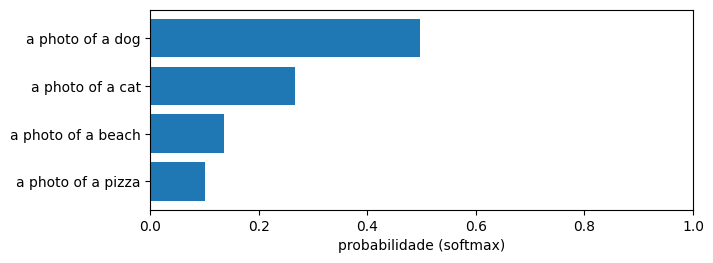

 49.6%   cosseno 0.220   a photo of a dog
 26.7%   cosseno 0.214   a photo of a cat
 10.1%   cosseno 0.204   a photo of a pizza
 13.6%   cosseno 0.207   a photo of a beach


In [5]:
@torch.no_grad()
def classificar(imagem, rotulos, mostrar=True):
    entrada = proc(text=rotulos, images=imagem, return_tensors="pt", padding=True).to(dev)
    saida = modelo(**entrada)
    probs = saida.logits_per_image.softmax(dim=1)[0].cpu().numpy()
    cos = (saida.image_embeds @ saida.text_embeds.T)[0].cpu().numpy()
    if mostrar:
        ordem = np.argsort(probs)
        plt.figure(figsize=(7, 0.45 * len(rotulos) + 0.8))
        plt.barh([rotulos[i] for i in ordem], probs[ordem])
        plt.xlim(0, 1); plt.xlabel("probabilidade (softmax)")
        plt.show()
    return probs, cos


img = abrir(enviados[0])
rotulos = ["a photo of a dog", "a photo of a cat", "a photo of a pizza", "a photo of a beach"]
probs, cos = classificar(img, rotulos)
for r, p, c in zip(rotulos, probs, cos):
    print(f"{p:6.1%}   cosseno {c:.3f}   {r}")

**Troque os rótulos** para descrever o conteúdo das suas fotos e rode de novo para cada uma.

### 3.1 Olhando por dentro: os tensores

A célula abaixo mostra o formato de cada etapa. Compare com o caminho da seção 1.2.

In [6]:
entrada = proc(text=rotulos, images=img, return_tensors="pt", padding=True)
_, canais, altura, largura = entrada["pixel_values"].shape
print(f"pixel_values: {tuple(entrada['pixel_values'].shape)} -> 1 imagem, {canais} canais de cor, {altura} x {largura} pixels")
print(f"input_ids:    {tuple(entrada['input_ids'].shape)} -> {len(rotulos)} rótulos, cada um com {entrada['input_ids'].shape[1]} tokens (com padding)")
print("Tokens do primeiro rótulo:", proc.tokenizer.convert_ids_to_tokens(entrada["input_ids"][0]))

with torch.no_grad():
    saida = modelo(**entrada.to(dev))
print(f"\nimage_embeds: {tuple(saida.image_embeds.shape)} -> 1 vetor com {saida.image_embeds.shape[1]} números")
print(f"text_embeds:  {tuple(saida.text_embeds.shape)} -> 1 vetor por rótulo")
print(f"Comprimento do vetor da imagem: {saida.image_embeds.norm().item():.3f} (normalizado)")
print("Primeiros 8 números do vetor da imagem:", np.round(saida.image_embeds[0, :8].cpu().numpy(), 3))

pixel_values: (1, 3, 224, 224) -> 1 imagem, 3 canais de cor, 224 x 224 pixels
input_ids:    (4, 7) -> 4 rótulos, cada um com 7 tokens (com padding)
Tokens do primeiro rótulo: ['<|startoftext|>', 'a</w>', 'photo</w>', 'of</w>', 'a</w>', 'dog</w>', '<|endoftext|>']

image_embeds: (1, 512) -> 1 vetor com 512 números
text_embeds:  (4, 512) -> 1 vetor por rótulo
Comprimento do vetor da imagem: 1.000 (normalizado)
Primeiros 8 números do vetor da imagem: [ 0.032  0.007 -0.028  0.009 -0.045 -0.001  0.     0.064]


**Leitura:** a foto, que tinha milhões de pixels, vira um único vetor de 512 números. Esses números não têm significado isolado; o que importa é a **direção** do vetor, comparada com a dos vetores de texto. Os tokens começam com `<|startoftext|>` e terminam com `<|endoftext|>`, marcadores de início e fim de frase; o símbolo `</w>` indica fim de palavra.

**Para pensar** (não precisa escrever a resposta): em qual das suas 3 fotos o rótulo vencedor teve a maior probabilidade? E o maior cosseno? São a mesma foto?

## 4. De onde vem a probabilidade?

Vamos refazer a conta da seção 1.3 à mão para tirar a mágica: cosseno, multiplicado pela escala aprendida, e depois softmax. O resultado deve bater com o da função.

- `modelo.logit_scale` guarda o logaritmo da escala, porque é mais estável aprender o logaritmo durante o treino; `.exp()` desfaz o logaritmo.
- `torch.tensor(cos * escala).softmax(dim=0)` aplica a fórmula do softmax sobre os rótulos.

In [7]:
escala = modelo.logit_scale.exp().item()
probs_mao = torch.tensor(cos * escala).softmax(dim=0).numpy()
print(f"Escala aprendida (inverso da temperatura): {escala:.1f}")
print("Cossenos:          ", np.round(cos, 3))
print("Probabilidade (mão):", np.round(probs_mao, 3))
print("Probabilidade (CLIP):", np.round(probs, 3))

Escala aprendida (inverso da temperatura): 100.0
Cossenos:           [0.22  0.214 0.204 0.207]
Probabilidade (mão): [0.496 0.267 0.101 0.136]
Probabilidade (CLIP): [0.496 0.267 0.101 0.136]


**Leitura:** os cossenos costumam ser números próximos entre si (por exemplo, entre 0,15 e 0,30). A escala, em torno de 100, amplia essas pequenas diferenças, e o softmax transforma a maior delas em uma probabilidade alta. Por isso uma diferença pequena de cosseno pode virar 90% contra 10%.

## 5. Português contra inglês

O CLIP original foi treinado majoritariamente com legendas em inglês. Compare os mesmos rótulos nos dois idiomas, na mesma imagem.

Há dois motivos para o português sair pior:
- **Dados de treino.** O modelo viu muito menos legendas em português, então os vetores das frases em português ficam mal posicionados no espaço compartilhado.
- **Tokenizador.** O vocabulário foi montado a partir de textos em inglês. Palavras em português costumam ser quebradas em mais pedaços, cada um com menos significado. A célula abaixo mostra quantos tokens cada frase gera; o símbolo `</w>` marca o fim de uma palavra.

In [8]:
for frase in ["a photo of a dog", "uma foto de um cachorro", "a photo of a strawberry", "uma foto de um morango"]:
    tokens = proc.tokenizer.tokenize(frase)
    print(f"{len(tokens):2d} tokens  {frase:<26} {tokens}")

 5 tokens  a photo of a dog           ['a</w>', 'photo</w>', 'of</w>', 'a</w>', 'dog</w>']
 7 tokens  uma foto de um cachorro    ['uma</w>', 'foto</w>', 'de</w>', 'um</w>', 'ca', 'chor', 'ro</w>']
 5 tokens  a photo of a strawberry    ['a</w>', 'photo</w>', 'of</w>', 'a</w>', 'strawberry</w>']
 6 tokens  uma foto de um morango     ['uma</w>', 'foto</w>', 'de</w>', 'um</w>', 'mor', 'ango</w>']


In [9]:
en = ["a photo of a dog", "a photo of a cat", "a photo of a car", "a photo of food"]
pt = ["uma foto de um cachorro", "uma foto de um gato", "uma foto de um carro", "uma foto de comida"]

for caminho in enviados:
    im = abrir(caminho)
    p_en, _ = classificar(im, en, mostrar=False)
    p_pt, _ = classificar(im, pt, mostrar=False)
    print(f"\n{caminho}")
    for a, b, x, y in zip(en, pt, p_en, p_pt):
        print(f"  {x:6.1%} {a:<22} | {y:6.1%} {b}")


bananas.jpg
    1.9% a photo of a dog       |   3.9% uma foto de um cachorro
    1.0% a photo of a cat       |   2.2% uma foto de um gato
    1.0% a photo of a car       |   2.5% uma foto de um carro
   96.1% a photo of food        |  91.4% uma foto de comida

cachorro.jpg
   99.1% a photo of a dog       |  86.1% uma foto de um cachorro
    0.3% a photo of a cat       |   0.8% uma foto de um gato
    0.0% a photo of a car       |   0.1% uma foto de um carro
    0.6% a photo of food        |  13.0% uma foto de comida

cubo-magico.jpg
   20.8% a photo of a dog       |  14.9% uma foto de um cachorro
    4.7% a photo of a cat       |   5.2% uma foto de um gato
   50.6% a photo of a car       |  33.0% uma foto de um carro
   23.9% a photo of food        |  46.8% uma foto de comida


### Minha comparação entre português e inglês

| Foto | Rótulo esperado | Inglês | Português |
| --- | --- | --- | --- |
| bananas.jpg | food / comida | 96,1% | 91,4% |
| cachorro.jpg | dog / cachorro | 99,1% | 86,1% |
| cubo-magico.jpg | nenhum dos quatro | vence car, 50,6% | vence comida, 46,8% |

Nas duas fotos que tinham um rótulo certo, o inglês deu mais confiança à classe correta: 4,7 pontos a mais nas bananas e 13 pontos a mais no cachorro. No cachorro, "uma foto de comida" chegou a 13,0%, contra 0,6% em inglês. O cubo mágico não se encaixava em nenhum dos quatro rótulos, e o vencedor mudou com o idioma: carro em inglês, comida em português. Mesmo sem nenhuma opção certa, o softmax apontou um vencedor com cerca de metade da probabilidade.

**O que observar:** em inglês, a probabilidade da classe certa costuma ser mais alta e mais consistente. Isso é **viés de idioma** dos dados de treino, uma limitação que vale para muitos modelos multimodais. Existem versões multilíngues do CLIP para contornar isso.

**Para pensar** (não precisa escrever a resposta): em quantas das suas fotos o rótulo vencedor mudou ao trocar de idioma? Em uma aplicação para usuários brasileiros, como você contornaria esse viés? (Pistas: traduzir o rótulo antes de enviar, ou usar um modelo multilíngue.)

## 6. O template de prompt importa

O artigo do CLIP mostrou que escrever "a photo of a {classe}" funciona melhor que a palavra solta. Por quê? As legendas da internet quase nunca são uma palavra isolada; são frases. O template deixa o rótulo **parecido com o que o modelo viu no treino**. Ele também tira ambiguidades: "crane" pode ser uma garça ou um guindaste, mas "a photo of a crane, a type of bird" não. Os autores ganharam alguns pontos de acurácia só escolhendo bons templates, e mais ainda com a **média de vários templates** (por exemplo, "a photo of a", "a drawing of a", "a close-up photo of a").

Isso é **engenharia de prompt**, a mesma ideia que vamos usar com LLMs na Prática 2. Teste.

In [10]:
classes = ["dog", "cat", "car", "food"]
p_solta, _ = classificar(img, classes, mostrar=False)
p_tpl, _ = classificar(img, [f"a photo of a {c}" for c in classes], mostrar=False)
for c, a, b in zip(classes, p_solta, p_tpl):
    print(f"{c:<6} palavra solta {a:6.1%} | com template {b:6.1%}")

dog    palavra solta   4.3% | com template   1.3%
cat    palavra solta   2.0% | com template   0.7%
car    palavra solta   3.3% | com template   0.6%
food   palavra solta  90.4% | com template  97.4%


## 7. Quando nenhum rótulo está certo

Use rótulos que **não têm nada a ver** com a sua foto. O softmax ainda vai escolher um vencedor com confiança, porque, por construção, ele **sempre distribui 100% entre os rótulos oferecidos**: não existe a opção "nenhum". Compare com os cossenos, que contam outra história: eles medem o quanto a imagem e o texto combinam de forma absoluta.

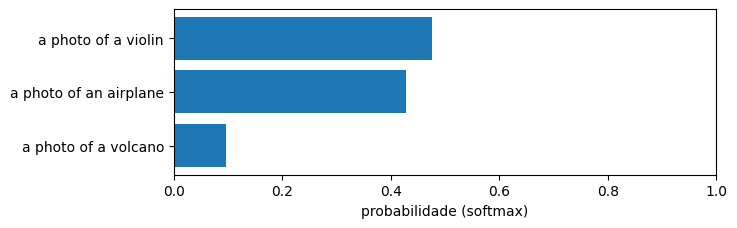

Cossenos com rótulos errados: [0.214 0.215 0.199]
Cossenos com rótulos certos (seção 3): [0.22  0.214 0.204 0.207]


In [11]:
errados = ["a photo of an airplane", "a photo of a violin", "a photo of a volcano"]
p_err, c_err = classificar(img, errados)
print("Cossenos com rótulos errados:", np.round(c_err, 3))
print("Cossenos com rótulos certos (seção 3):", np.round(cos, 3))

**Lição para aplicações reais:** nunca confie só no softmax. Em produção, inclua uma classe de rejeição ou use um limiar de similaridade do cosseno, calibrado com exemplos reais, para responder "nenhuma das opções". **Calibrar** significa medir os cossenos de rótulos certos e errados em várias fotos e escolher o valor que melhor separa os dois grupos.

**Para pensar** (não precisa escrever a resposta): qual foi a probabilidade do rótulo errado vencedor? E a diferença entre o maior cosseno da seção 3 e o maior cosseno desta seção?

## 8. Bônus: buscar imagens com uma frase

O mesmo espaço compartilhado permite o caminho inverso: dada uma frase, encontrar a imagem mais parecida. É a ideia central do RAG multimodal do Encontro 4.

**Como a função `buscar` funciona:** ela calcula o vetor da frase e o de cada imagem, faz o produto escalar `text_embeds @ image_embeds.T` (um cosseno por imagem) e ordena do maior para o menor com `np.argsort(-cos)`; o sinal de menos inverte a ordem crescente padrão. Em um sistema real, os vetores das imagens são calculados uma única vez e guardados em um **banco vetorial**, e só o vetor da frase é calculado a cada busca.

In [12]:
@torch.no_grad()
def buscar(frase, caminhos):
    imagens = [abrir(c) for c in caminhos]
    entrada = proc(text=[frase], images=imagens, return_tensors="pt", padding=True).to(dev)
    saida = modelo(**entrada)
    cos = (saida.text_embeds @ saida.image_embeds.T)[0].cpu().numpy()
    for i in np.argsort(-cos):
        print(f"cosseno {cos[i]:.3f}  {caminhos[i]}")


buscar("a photo taken outdoors", enviados)

cosseno 0.210  cubo-magico.jpg
cosseno 0.209  bananas.jpg
cosseno 0.194  cachorro.jpg


## 9. Quiz

Responda às 5 perguntas abaixo na célula de respostas, com a letra da alternativa certa (a, b, c ou d). Cada pergunta tem uma única resposta correta. Depois, rode a célula de conferência e salve o notebook para enviar.

**1. O que o CLIP aprende durante o treino?**

- **a)** Classificar imagens em uma lista fixa de mil categorias
- **b)** Aproximar, em um mesmo espaço de vetores, imagens e legendas que combinam
- **c)** Gerar imagens a partir de uma frase
- **d)** Traduzir legendas do inglês para outros idiomas

**2. Por que, no CLIP, o cosseno pode ser calculado como um simples produto escalar?**

- **a)** Porque os vetores são normalizados para comprimento 1
- **b)** Porque as imagens são reduzidas para 224 × 224 pixels
- **c)** Porque o softmax já foi aplicado
- **d)** Porque o cálculo é feito na GPU

**3. Você usou rótulos que não têm nada a ver com a foto. O que o softmax faz?**

- **a)** Devolve 0% para todos os rótulos
- **b)** Responde "nenhuma das opções"
- **c)** Ainda distribui 100% entre os rótulos e aponta um vencedor
- **d)** Gera um erro

**4. Por que "a photo of a dog" costuma funcionar melhor do que só "dog"?**

- **a)** Porque frases mais longas sempre ganham
- **b)** Porque a frase se parece com as legendas que o modelo viu no treino
- **c)** Porque o modelo só aceita frases com cinco palavras
- **d)** Porque o template ativa a GPU

**5. Com uma imagem de 224 × 224 pixels e patches de 32 × 32, quantos patches o modelo processa?**

- **a)** 7
- **b)** 32
- **c)** 49
- **d)** 224

In [13]:
RESPOSTAS = {
    1: "b",   # a, b, c ou d
    2: "a",   # a, b, c ou d
    3: "c",   # a, b, c ou d
    4: "b",   # a, b, c ou d
    5: "c",   # a, b, c ou d
}

In [14]:
# Conferência: mostra seu nome e suas respostas e avisa o que falta (não mostra a nota)
faltando = [q for q, r in RESPOSTAS.items() if str(r).strip().lower() not in ("a", "b", "c", "d")]
print("Aluno:", ALUNO or "NOME NÃO PREENCHIDO: volte à célula de identificação, no início")
if MATRICULA:
    print("Matrícula:", MATRICULA)
print("Respostas:", {q: str(r).strip().lower() for q, r in RESPOSTAS.items()})
if faltando:
    print("Atenção, perguntas sem resposta válida:", faltando)
else:
    print("Quiz completo. Salve o notebook (Arquivo > Fazer download > .ipynb) e envie pelo portal.")

Aluno: Tales Rodrigo Ferreira Kerschner
Respostas: {1: 'b', 2: 'a', 3: 'c', 4: 'b', 5: 'c'}
Quiz completo. Salve o notebook (Arquivo > Fazer download > .ipynb) e envie pelo portal.


## Para entregar

- [ ] Nome preenchido na célula de identificação
- [ ] Resultados com 3 fotos suas (seção 3)
- [ ] Tabela português contra inglês (seção 5)
- [ ] Quiz respondido e conferido (seção 9)

Antes de baixar, use **Ambiente de execução > Reiniciar e executar tudo** para garantir que o notebook roda do começo ao fim.